# TNM112 -- Lab 2

### Data generation
Look through the "data_generator.py" code to understand how the dataset is generated and plotted.

A dataset can be generated with a randomly selected subset of training images, and with a specified fraction used to formulate a validation set. Here, we use the MNIST dataset of handwritten digits.

arrived here
Data specification:
	Dataset type:          mnist
	Number of channels (C): 1
	Training data shape:   (54000, 1, 28, 28) [NCHW]
	Validation data shape: (6000, 1, 28, 28) [NCHW]
	Test data shape:       (10000, 1, 28, 28) [NCHW]


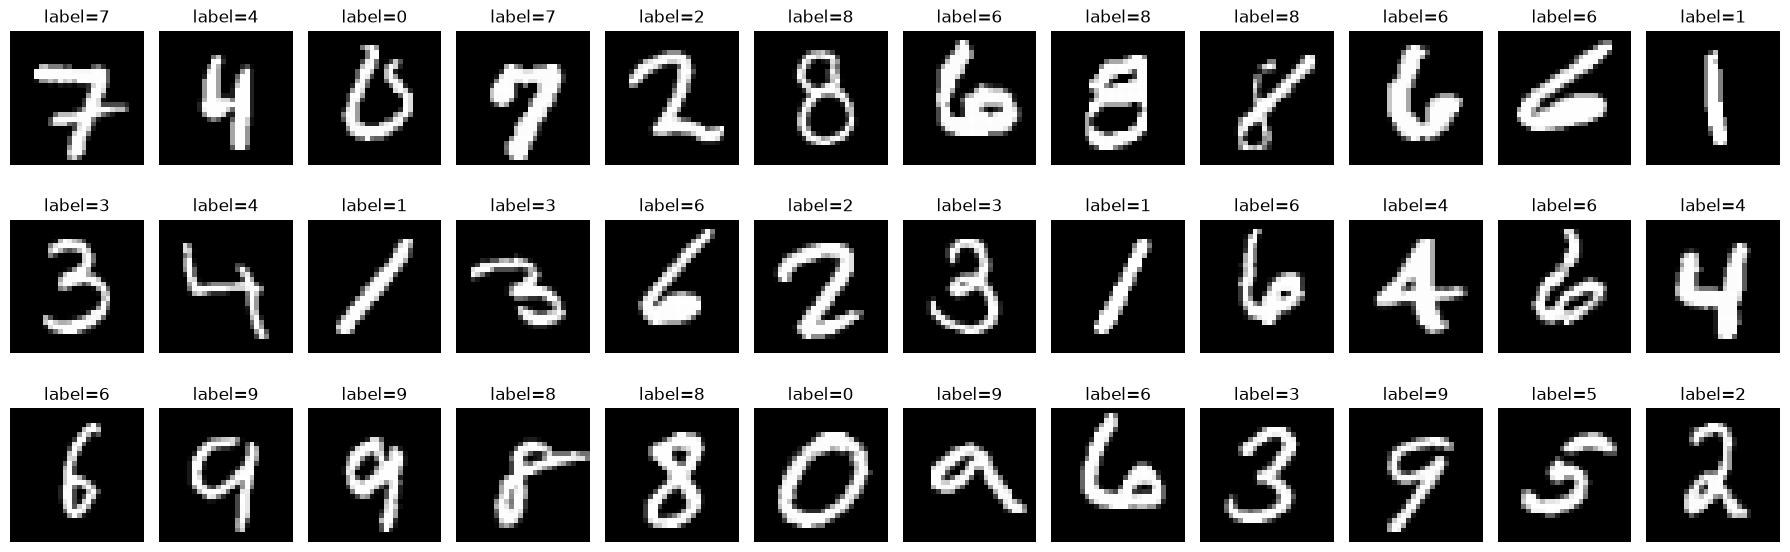

In [20]:
import data_generator

data = data_generator.DataGenerator()
data.generate(dataset='mnist', N_valid=0.1)
data.plot()

### PyTorch CNN
A small CNN in Pytorch, trained with cross-entropy loss

We use the functions in 'util.py' to evaluate the model and plot the training progress.

In the next cell, we define our training loop. Study it carefully, and you are encouraged to change it (e.g. change optimizer or adding weight decay).

In [21]:
# Study this cell. Here we define the training loop of our model

import torch
import torch.nn as nn

def train_model(
    model,
    dataset,
    epochs=10,
    batch_size=128,
    lr=1e-3,
    device=None,
    verbose=True,
):

  if device is None:
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
  model.to(device)

  # get dataloaders
  train_loader = dataset.get_loader('train', batch_size=batch_size, shuffle=True)
  val_loader = dataset.get_loader('valid', batch_size=batch_size, shuffle=False)

  # define loss function and optimizer
  criterion = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  # define dict to log training history
  history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

  for epoch in range(epochs):
    # --- Training phase ---
    model.train()
    running_loss, running_correct, total_train = 0.0, 0, 0

    for inputs, targets in train_loader:
      inputs, targets = inputs.to(device), targets.to(device)

      optimizer.zero_grad()
      outputs = model(inputs)
      loss = criterion(outputs, targets)
      loss.backward()
      optimizer.step()

      running_loss += loss.item() * inputs.size(0)
      preds = outputs.argmax(dim=1)
      running_correct += (preds == targets).sum().item()
      total_train += inputs.size(0)

    train_loss = running_loss / total_train
    train_acc = running_correct / total_train

    # --- Validation phase ---
    model.eval()
    val_loss, val_correct, total_val = 0.0, 0, 0

    with torch.no_grad():
      for inputs, targets in val_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        val_loss += loss.item() * inputs.size(0)
        preds = outputs.argmax(dim=1)
        val_correct += (preds == targets).sum().item()
        total_val += inputs.size(0)

    val_loss = val_loss / total_val
    val_acc = val_correct / total_val

    history['loss'].append(train_loss)
    history['accuracy'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)

    if verbose:
      print(
          f'Epoch {epoch+1:2d}/{epochs:2d} | '
          f'Loss: {train_loss:.4f} - Acc: {100*train_acc:.2f}% | '
          f'Val Loss: {val_loss:.4f} - Val Acc: {100*val_acc:.2f}%'
      )

  return {'history': history}

Sequential(
  (0): Conv2d(1, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(4, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=392, out_features=10, bias=True)
)
Epoch  1/10 | Loss: 0.5745 - Acc: 85.15% | Val Loss: 0.1863 - Val Acc: 94.30%
Epoch  2/10 | Loss: 0.1564 - Acc: 95.33% | Val Loss: 0.1265 - Val Acc: 96.02%
Epoch  3/10 | Loss: 0.1175 - Acc: 96.45% | Val Loss: 0.0985 - Val Acc: 96.83%
Epoch  4/10 | Loss: 0.0994 - Acc: 96.96% | Val Loss: 0.0877 - Val Acc: 97.38%
Epoch  5/10 | Loss: 0.0873 - Acc: 97.43% | Val Loss: 0.0795 - Val Acc: 97.47%
Epoch  6/10 | Loss: 0.0793 - Acc: 97.62% | Val Loss: 0.0792 - Val Acc: 97.55%
Epoch  7/10 | Loss: 0.0735 - Acc: 97.76% | Val Loss: 0.0720 - Val Acc: 97.75%
Epoch  

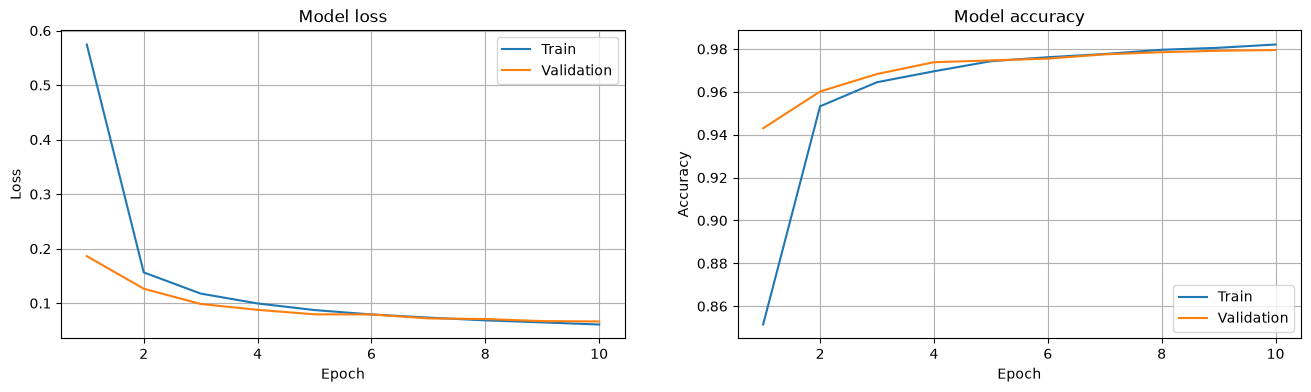

In [22]:
import util
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Calculate linear layer input dimension dynamically
def compute_flattened_dim(in_channels, img_h, img_w):
  sample = torch.zeros(1, in_channels, img_h, img_w)
  features = nn.Sequential(
      nn.Conv2d(in_channels, 4, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),
      nn.Conv2d(4, 8, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),
      nn.Flatten(),
  )
  return features(sample).shape[1]

_, C, H, W = data.x_train.shape
flat_dim = compute_flattened_dim(C, H, W)

# 2. Build model architecture
# Note: No Softmax at the end; CrossEntropyLoss expects raw unnormalized logits
model = nn.Sequential(
    nn.Conv2d(C, 4, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(4, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(flat_dim, data.K),
).to(device)

print(model)

# 3. Train and evaluate
log = train_model(
    model, data, epochs=10, batch_size=128, lr=1e-3, device=device
)
util.evaluate(model, data, final=True, device=device)
util.plot_training(log)

### Our CNN

#### Task 1
Implement the following functions in cnn.py: 'activation', 'conv2d_layer', 'pool2d_layer', 'flatten_layer', 'dense_layer', and 'evaluate'. Additionally, compute the number of weights in the model, in the function 'setup_model'.

For the 'activation' and 'dense_layer' functions you can use code that you wrote in Lab 1. For the 'evaluate' function you can use the code from Lab 1 for the accuracy. However, now we have trained with the cross-entropy loss, so you should evaluate this loss function through our CNN.

When you have finished the implementation, you should be able to run this code and get the same result as with the Keras model above. However, our code is not optimized, nor parallelized, so it will be rather slow to process the full dataset - for the training set, you can cap it at 5000 samples. In order to facilitate comparisons when you implement the functions, please have a look in the next cell below. 

In [23]:
import importlib
import cnn
importlib.reload(cnn)
importlib.reload(util)

# Get the weight matrices and biases of the trained Keras model
W, b, lname = util.get_weights(model)

# This is our implementation of a CNN, which we set to use the dataset we generated
cnn = cnn.CNN(data, verbose=True)

# Assign the weights and biases to the CNN and specify the activation function
cnn.setup_model(W, b, lname, activation='relu')

# Evaluate the model (accuracy on the training and test data)
cnn.evaluate()

Number of model weights:  4266
Model performance:
sample 0 of 54000
sample 1000 of 54000
sample 2000 of 54000
sample 3000 of 54000
sample 4000 of 54000
sample 5000 of 54000
sample 6000 of 54000
sample 7000 of 54000
sample 8000 of 54000
sample 9000 of 54000
sample 10000 of 54000
sample 11000 of 54000
sample 12000 of 54000
sample 13000 of 54000
sample 14000 of 54000
sample 15000 of 54000
sample 16000 of 54000
sample 17000 of 54000
sample 18000 of 54000
sample 19000 of 54000
sample 20000 of 54000
sample 21000 of 54000
sample 22000 of 54000
sample 23000 of 54000
sample 24000 of 54000
sample 25000 of 54000
sample 26000 of 54000
sample 27000 of 54000
sample 28000 of 54000
sample 29000 of 54000
sample 30000 of 54000
sample 31000 of 54000
sample 32000 of 54000
sample 33000 of 54000
sample 34000 of 54000
sample 35000 of 54000
sample 36000 of 54000
sample 37000 of 54000
sample 38000 of 54000
sample 39000 of 54000
sample 40000 of 54000
sample 41000 of 54000
sample 42000 of 54000
sample 43000 of 5

### Evaluation of our CNN layers

#### Task 1
As part of the implementation of the different layers in 'cnn.py', you can use the below code to compare the output of a randomly initialized  model and our CNN, for a single image. This is fast to compute, which will be convenient to check that your layers are correctly implemented.

In [24]:
import importlib
import cnn
import numpy as np
import torch
import torch.nn as nn
import util
import data_generator
#hahahahahah

importlib.reload(cnn)
importlib.reload(util)

# Specify a test layer for comparison: 'conv', 'pool', 'flatten', or 'dense'
test_layer = 'conv'

# Generate the data if this cell is run before the notebook's data cell.
if 'data' not in globals():
  data = data_generator.DataGenerator()
  data.generate(dataset='mnist', N_valid=0.1)

# Input channels and dimensions from our data generator (C, H, W)
C, H, W_dim = data.x_train.shape[1:]

layers = []

# Test conv layer
#   - We apply normal initialization to the bias also,
#     otherwise it would be difficult to see the impact
#     of how you apply the bias (it is initialized to 0 by default)
if test_layer == 'conv':
  conv = nn.Conv2d(C, 4, kernel_size=3, padding=1)
  # Initialize bias with a normal distribution
  nn.init.normal_(conv.bias)
  layers.extend([conv, nn.ReLU()])

  # To test a second conv layer, uncomment below:
  # conv2 = nn.Conv2d(4, 4, kernel_size=3, padding=1)
  # nn.init.normal_(conv2.bias)
  # layers.extend([conv2, nn.ReLU()])

# Test pooling layer
elif test_layer == 'pool':
  layers.append(nn.MaxPool2d(kernel_size=2))

# Test flattening layer
elif test_layer == 'flatten':
  layers.append(nn.Flatten())

# Test dense layer
#   - We need to first flatten the image input to apply a dense layer
#   - Make sure that your flatten layer works before testing the dense layer
elif test_layer == 'dense':
  # Compute flattened dimension
  flat_features = C * H * W_dim
  linear = nn.Linear(flat_features, 10)
  nn.init.normal_(linear.bias)
  layers.extend([nn.Flatten(), linear, nn.ReLU(dim=1)])

print(layers)

# Build the PyTorch test model
model = nn.Sequential(*layers)
model.eval()

# Test sample: (C, H, W)
x = data.x_train[0]

# PyTorch forward pass: unsqueeze adds the batch dimension -> (1, C, H, W)
x_torch = torch.from_numpy(x).unsqueeze(0).float()
with torch.no_grad():
  y1 = model(x_torch).numpy()

# Prediction with our network
W, b, lname = util.get_weights(model)
numpy_cnn = cnn.CNN(data)
numpy_cnn.setup_model(W, b, lname, activation='relu')
y2 = numpy_cnn.feedforward_sample(x)

print('Evaluation of %s layer:'%test_layer)

# Check that the dimensionality is correct. The Keras
# model will have an extra first dimension due to the
# batch processing
print('\tShape of Pytorch output:  ', y1.shape)
print('\tShape of our output:    ', y2.shape)

# Print the absolute sum of output from the Keras
# model and our model. These should be the same if the
# implementation is correct
print('\tAbs sum of Pytorch model: ', np.sum(np.abs(y1)))
print('\tAbs sum of our model:   ', np.sum(np.abs(y2)))

# Print the absolute difference between the Keras
# model and our model. This should be very close
# to 0 if your implementation is correct. It could be
# a very minor difference due to numerical differences 
# (e.g., difference in precision used)
print('\tAbs difference:         ', np.sum(np.abs(y1-y2)))

[Conv2d(1, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)), ReLU()]
Number of model weights:  40
Evaluation of conv layer:
	Shape of Pytorch output:   (1, 4, 28, 28)
	Shape of our output:     (4, 28, 28)
	Abs sum of Pytorch model:  2612.1191
	Abs sum of our model:    2612.1191
	Abs difference:          1.719594e-05


### MNIST with limited training data
#### Task 2
In this experiment, we select a random subset from MNIST, with only 128 images. This is a very minimal dataset, but it is interesting to see how overfitting can be prevented with regularization strategies.

Your task is to expand the given network with different regularization strategies. You are free to choose which combination of strategies you want to use, for example augmentation layers, dropout, weight decay, batch normalization, etc. You can also expand the network with more layers, strided convolutions, or add skip-connections to facilitate optimization. Moreover, you can experiment with the number of training epochs and the batch size.

**Note that some changes, such as changing the optimizer, adding data augmentation, or adding a learning rate scheduler, need to be done by modifying the training function 'train_model'.**

Also, note that now we have specified the network in a sligthly different way. We explicitly formulate the input and output to the different layers. One motivation for this is that it is easier if we want to, e.g., add skip-connections.

During your development, you test the performance on the validation set (util.evaluate with the flag final=False). When you have found a good setup, run evaluation on the test set (final=True). Do this for at least 5 runs and report the average and the variance across models. Since the subset of 128 images is randomly selected and the optimization is stochastic, you will get slightly different values each time. Thus, averaging is important to get a robust indication of your model's performance. You can do this manually, or you can setup a for-loop to run a sequence of trainings, where you log the evaluation results for each model.

For the final results, you should aim at having an average accuracy of at least 85% (which is quite good considering that we are only training on 128 images).

arrived here
Data specification:
	Dataset type:          mnist
	Number of channels (C): 1
	Training data shape:   (128, 1, 28, 28) [NCHW]
	Validation data shape: (6000, 1, 28, 28) [NCHW]
	Test data shape:       (10000, 1, 28, 28) [NCHW]
CNNModel(
  (conv1): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3

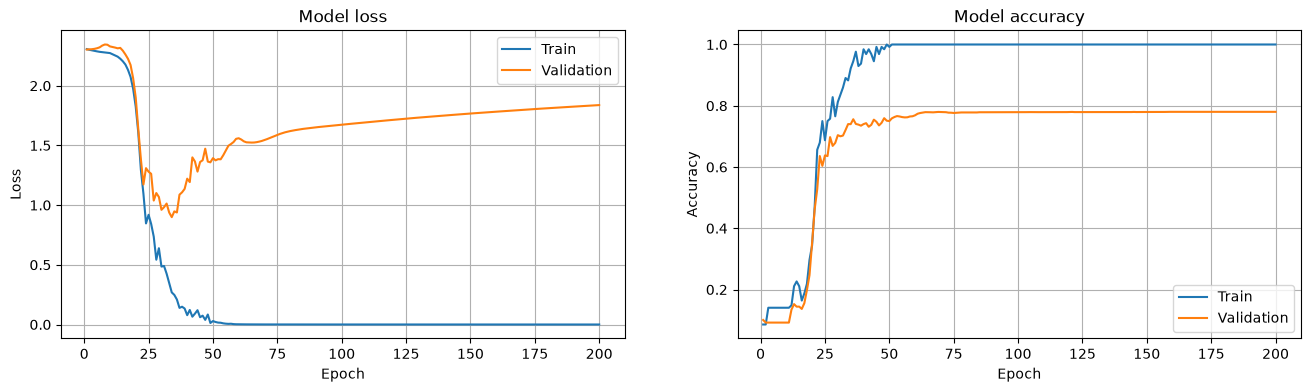

In [25]:
import data_generator
import numpy as np
import torch
import torch.nn as nn
import util

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# A block of convolutional layers followed by max pooling
def conv_block(in_channels, out_channels, N, kernel_size=(3, 3)):
  layers = []
  c_in = in_channels
  for _ in range(N):
    layers.append(
        nn.Conv2d(
            c_in,
            out_channels,
            kernel_size=kernel_size,
            padding=kernel_size[0] // 2,
        )
    )
    layers.append(nn.ReLU())
    c_in = out_channels
  layers.append(nn.MaxPool2d(kernel_size=(2, 2)))
  return nn.Sequential(*layers)
    
epochs = 200
batch_size = 64

# For setting up averaging over multiple training runs
#K = 5
#acc = np.zeros((K,2))
#for k in range(K):

# MNIST with 128 randomly selected training images
data = data_generator.DataGenerator()
data.generate(dataset='mnist', N_train=128)

# Model definition matching the original functional layout
class CNNModel(nn.Module):

  def __init__(self, in_channels, num_classes):
    super().__init__()
    self.conv1 = conv_block(
        in_channels, out_channels=8, N=2, kernel_size=(3, 3)
    )
    self.conv2 = conv_block(8, out_channels=16, N=2, kernel_size=(3, 3))
    self.conv3 = conv_block(16, out_channels=32, N=2, kernel_size=(3, 3))
    self.flatten = nn.Flatten()

    # Dynamic calculation of flattened features
    with torch.no_grad():
      dummy = torch.zeros(1, in_channels, 28, 28)
      feat_dim = self.flatten(self.conv3(self.conv2(self.conv1(dummy)))).shape[
          1
      ]

    self.dense1 = nn.Linear(feat_dim, 512)
    self.relu = nn.ReLU()
    self.dense2 = nn.Linear(512, num_classes)

  def forward(self, x):
    x = self.conv1(x)
    x = self.conv2(x)
    x = self.conv3(x)
    x = self.flatten(x)
    x = self.relu(self.dense1(x))
    y = self.dense2(x)  # Raw logits for CrossEntropyLoss
    return y

model = CNNModel(in_channels=data.C, num_classes=data.K).to(device)
print(model)

# Train the model
log = train_model(
    model,
    data,
    epochs=epochs,
    batch_size=batch_size,
    lr=1e-3,
    device=device,
)

util.evaluate(model, data, final=False, device=device)
util.plot_training(log)

# When you are finished with hyper-parameter tuning, you should evaluate
# your model on the test set, and average over 5 trainings. If you want
# to do this automatically, you can setup a foor loop and store each evaluation
#acc[k,:] = util.evaluate(model, data, final=True)

### Tumor classification in digital pathology
#### Task 3
In this task, we will look at a more difficult task, using the PatchCamelyon dataset. This contains tissue samples from breast lymph nodes, which could either be healthy or contain tumor tissue, i.e. this is a binary classification problem. For this reason, it is valuable to also evaluate the AU-ROC, which can be passed to our evaluate method.

You are provided with the training and validation set. These have been cropped to 32x32 pixels, to make it a bit less resource demanding to train. The test set is also provided, but without labels.

Your task is to setup a Pytorch model to achieve the best possible performance on the validation set. You are free to choose how to do this, e.g., by means of regularization and network specifications. You can, for example, use your results from Task 2 as a starting point, but you should also think around how this problem differs from the MNIST classification. For example, in this case the orientation of images has no meaning, so you can randomly flip images both horizontally and vertically. You can also, e.g., explore augmentation by means of changing the image contrast and brightness.

When you are finished with your development, you should run the 'util.pred_test' (at the bottom of the cell), to produce a CSV file with predictions of the test set. The exported CSV file should be uploaded to the Kaggle challenge, as described in the lab information. You need to train the model and export a CSV file 5 times, in order to have a good estimate for your model's performance. There are no requirements on how well your model should perform, as long as it is well above random guessing (50% accuracy).

In [26]:
import data_generator
import numpy as np
import torch
import torch.nn as nn
import util

importlib.reload(util)
    
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

epochs = 10
batch_size = 128

# Load the PatchCamyleon dataset
# In this dataset, we don't have labels for the test set.
# Do your development by monitoring the validation performance,
# and when you are finished you will run predictions on the test
# set and produce a CSV file that you can upload to Kaggle.
data = data_generator.DataGenerator()
data.generate(dataset='patchcam')
data.plot()

# TODO: Build your network here
C, H, W = data.x_train.shape[1:]  # (3, 32, 32)
flat_features = C * H * W

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(flat_features, data.K),  # Output raw logits (Batch, K)
).to(device)

print(model)

# Train the model
log = train_model(
    model,
    data,
    epochs=epochs,
    batch_size=batch_size,
    lr=1e-3,
    device=device,
)


# Evaluate on validation set
util.evaluate(model, data, final=False, device=device, auc=True)
util.plot_training(log)

# TODO: When you have finished your model development, you should 
# run inference on the test set and export a CSV file that can be 
# uploaded to Kaggle
#util.pred_test(model, data, name='your_submission.csv')

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'patchcam/train.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)